# Previsão da qualidade de vinhos (Vinho Verde) a partir de propriedades físico-químicas

- Variável-alvo: quality (numérica contínua, nota de qualidade de 0 a 10)
- Features: 11 atributos físico-químicos (acidez fixa, acidez volátil, ácido cítrico, açúcar residual, cloretos, dióxido de enxofre livre e total, densidade, pH, sulfatos, álcool) + color (tipo do vinho: tinto ou branco)
- Objetivo: dado um conjunto de medidas físico-químicas de um vinho, o modelo deve estimar corretamente sua nota de qualidade
- Algoritmo: Regressão Linear, da mesma família (Modelos Lineares Generalizados) da Regressão Logística apresentada no seminário


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/klaytoncastro/idp-machinelearning/main/winequality/winequality-merged.csv"
df = pd.read_csv(url)

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,white
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,white
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,white
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,white


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [3]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6.497000e+03,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,1.710882,3.218501,0.531268,1.302704e+09,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,7.636088,0.160787,0.148806,3.184574e+10,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000e+00,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000e+00,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,1.030000e+01,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,1.130000e+01,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,103.898000,4.010000,2.000000,9.733333e+11,9.000000


In [4]:
df['quality'].value_counts().sort_index()

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

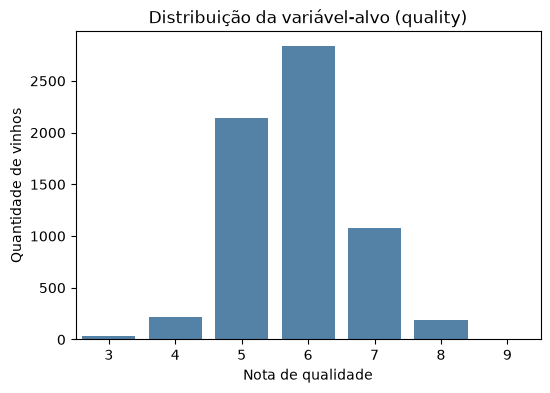

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(x='quality', data=df, color='steelblue')
plt.title('Distribuição da variável-alvo (quality)')
plt.xlabel('Nota de qualidade')
plt.ylabel('Quantidade de vinhos')
plt.show()

In [6]:
print("Valores nulos por coluna:")
print(df.isnull().sum().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())

Valores nulos por coluna:
0

Linhas duplicadas: 1176


In [7]:

# describe() mostrou max(alcohol) ~1e11 e max(density) ~104 -- fisicamente impossivel
# (alcool de vinho fica entre 8% e 15%, densidade fica perto da agua, 0.98-1.01)
print("Linhas com alcohol > 20 (%):", (df['alcohol'] > 20).sum())
print("Linhas com density > 1.5 (g/mL):", (df['density'] > 1.5).sum())

df.loc[df['alcohol'] > 20, ['alcohol']].head()


Linhas com alcohol > 20 (%): 40
Linhas com density > 1.5 (g/mL): 136


,alcohol
4315,1.289330e+02
4319,1.289333e+02
4323,1.146667e+02
4341,1.003333e+11
4353,1.143333e+11


In [8]:
# Remove linhas com valores fisicamente impossíveis (erro de digitação/escala nos dados brutos)
df = df[(df['alcohol'] <= 20) & (df['density'] <= 1.5)]

df[['alcohol', 'density']].describe()

,alcohol,density
count,6321.000000,6321.000000
mean,10.508307,0.994566
std,1.188949,0.002824
min,8.000000,0.987110
25%,9.500000,0.992290
50%,10.300000,0.994800
75%,11.300000,0.996800
max,14.900000,1.001000


In [9]:
# Agora sim, remoção das linhas duplicadas — evita que o mesmo padrão apareça no treino e no teste
df = df.drop_duplicates().reset_index(drop=True)
df.shape

(5187, 13)

In [10]:
# Codificação da variável categórica 'color' (tinto/branco) em binária
df['color'] = df['color'].map({'red': 0, 'white': 1})
df[['color']].value_counts()

color
1        3883
0        1304
Name: count, dtype: int64

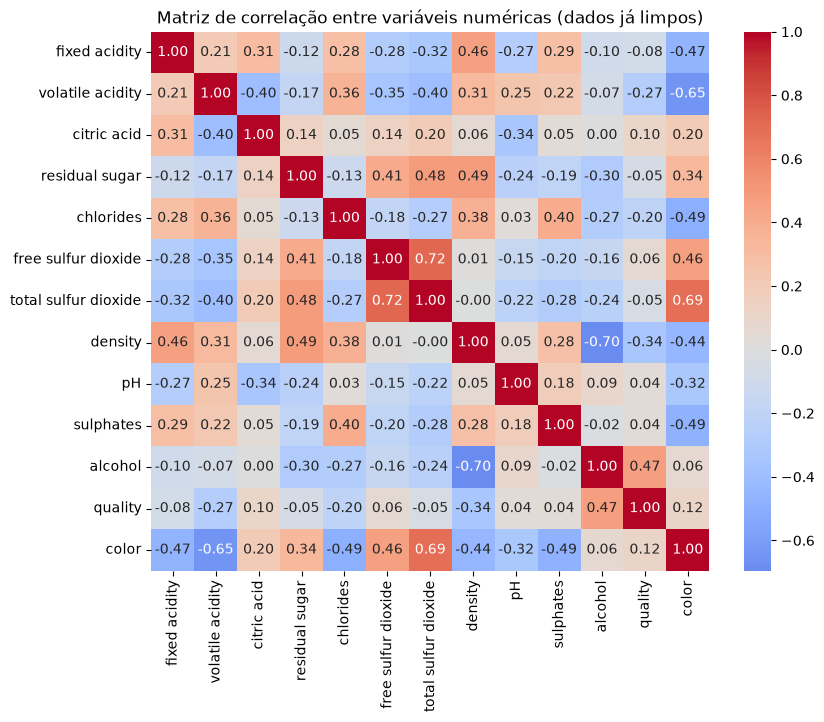

In [11]:
plt.figure(figsize=(9, 7))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação entre variáveis numéricas (dados já limpos)')
plt.show()

In [12]:
corr['quality'].sort_values(ascending=False)

quality                 1.000000
alcohol                 0.472977
color                   0.116641
citric acid             0.103357
free sulfur dioxide     0.055302
sulphates               0.041671
pH                      0.038595
total sulfur dioxide   -0.046588
residual sugar         -0.053252
fixed acidity          -0.081595
chlorides              -0.202001
volatile acidity       -0.266772
density                -0.343688
Name: quality, dtype: float64

In [13]:
X = df.drop(columns=['quality'])
y = df['quality']

X.shape, y.shape

((5187, 12), (5187,))

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((4149, 12), (1038, 12))

In [15]:
from sklearn.preprocessing import StandardScaler

# features em escalas bem diferentes (ex.: total sulfur dioxide vs chlorides) --
# padronizar deixa os coeficientes do modelo comparaveis entre si
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [16]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 0.12,-0.23, 0.03,..., 0.12, 0.22,-0.2 ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.804
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](12,)","[125.25,100.61, 81.78,..., 32.74, 22.33, 9.65]"


In [17]:
y_pred = modelo.predict(X_test_scaled)
y_pred[:10]

array([5.60342286, 5.64234905, 6.36187432, 6.09783204, 5.63925783,
       6.57024385, 6.03672274, 5.06916541, 5.69593778, 6.37685215])

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

MAE:  0.564
MSE:  0.524
RMSE: 0.724
R²:   0.287


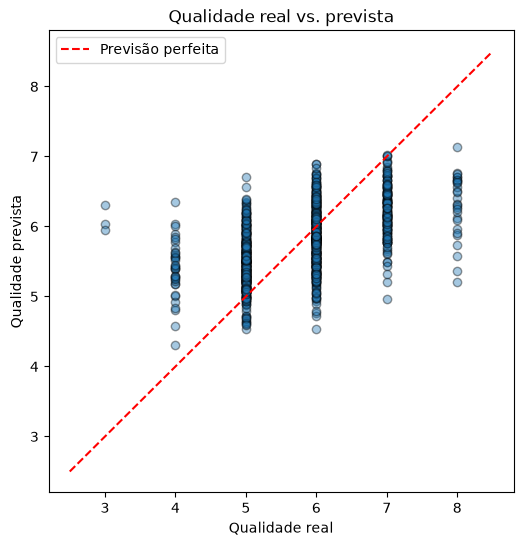

In [19]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.4, edgecolor='k')
lims = [y_test.min() - 0.5, y_test.max() + 0.5]
plt.plot(lims, lims, 'r--', label='Previsão perfeita')
plt.xlabel('Qualidade real')
plt.ylabel('Qualidade prevista')
plt.title('Qualidade real vs. prevista')
plt.legend()
plt.show()

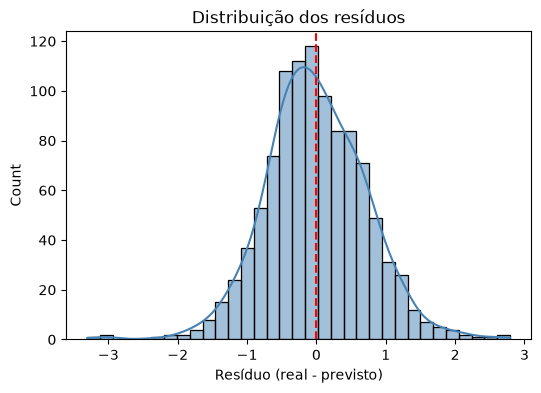

In [20]:
residuos = y_test - y_pred

plt.figure(figsize=(6, 4))
sns.histplot(residuos, kde=True, color='steelblue')
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Resíduo (real - previsto)')
plt.title('Distribuição dos resíduos')
plt.show()

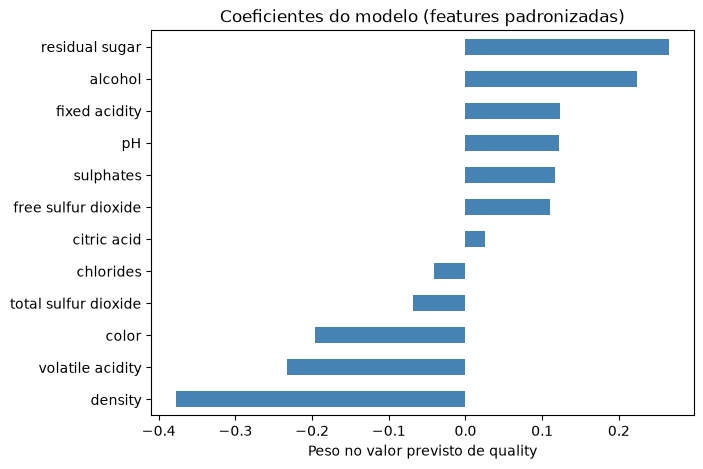

density                -0.377439
volatile acidity       -0.232730
color                  -0.196633
total sulfur dioxide   -0.067876
chlorides              -0.040423
citric acid             0.025622
free sulfur dioxide     0.110828
sulphates               0.116252
pH                      0.122014
fixed acidity           0.123466
alcohol                 0.223281
residual sugar          0.265572
dtype: float64

In [21]:
coeficientes = pd.Series(modelo.coef_, index=X.columns).sort_values()

plt.figure(figsize=(7, 5))
coeficientes.plot(kind='barh', color='steelblue')
plt.title('Coeficientes do modelo (features padronizadas)')
plt.xlabel('Peso no valor previsto de quality')
plt.show()

coeficientes

# Interpretação dos resultados

- **Desempenho do modelo:** o modelo de Regressão Linear obteve MAE de 0,564 e RMSE de 0,724 no conjunto de teste, ou seja, em média a nota prevista erra pouco mais de meio ponto na escala de 0 a 10. O R² de 0,287 mostra que o modelo explica cerca de 29% da variação da qualidade — uma parcela real, mas moderada, já que fatores sensoriais subjetivos do avaliador humano influenciam a nota e não estão presentes no dataset (apenas propriedades físico-químicas objetivas).

- **Impacto da limpeza dos dados:** a exploração revelou 176 linhas (~2,7% do dataset) com valores fisicamente impossíveis em `alcohol` (até ~10¹¹) e `density` (até ~104) — erros de escala no CSV bruto. Antes da limpeza, o mesmo modelo produzia R² ≈ 0,162 e MAE ≈ 0,616; depois de remover essas linhas, o R² subiu para 0,287 e a correlação real de `alcohol` com `quality`, antes mascarada pelos outliers, apareceu (de praticamente 0 para 0,47).

    | Métrica | Valor |
    |---------|-------|
    | MAE | 0,564 |
    | MSE | 0,524 |
    | RMSE | 0,724 |
    | R² | 0,287 |

- **Real vs. previsto e resíduos:** o gráfico de dispersão mostra os pontos concentrados ao redor da reta de previsão perfeita nas notas 5, 6 e 7 (as mais frequentes no dataset), mas o modelo tende a superestimar vinhos de nota baixa (3 e 4) e subestimar os de nota alta (8 e 9) — efeito de regressão à média, esperado quando há poucos exemplos nos extremos da distribuição do alvo. Os resíduos têm distribuição aproximadamente simétrica e centrada em zero, indicando que o modelo não está sistematicamente enviesado para cima ou para baixo.

- **Coeficientes (importância das features):** com as features padronizadas, os coeficientes ficam comparáveis entre si. `density` e `volatile acidity` têm os maiores pesos negativos — vinhos mais densos ou com maior acidez volátil tendem a nota mais baixa —, enquanto `alcohol` tem um dos maiores pesos positivos, confirmando que mais álcool está associado a notas melhores. Isso é coerente com a matriz de correlação calculada após a limpeza dos dados. O coeficiente positivo de `residual sugar`, aparentemente contraintuitivo isoladamente, é sintoma de multicolinearidade: essa variável é fortemente correlacionada com `density`, então parte do seu efeito é absorvida pela outra quando ambas entram no mesmo modelo.

- **Limitações:** o desempenho moderado reflete a natureza do problema — `quality` é uma nota sensorial subjetiva, com sobreposição natural entre notas vizinhas, e depende de fatores (aroma, sabor, textura) que não estão presentes no dataset. Além disso, a Regressão Linear assume relações estritamente lineares entre as features e o alvo; é provável que existam interações não lineares (por exemplo, entre acidez e pH) que um modelo mais flexível capturaria melhor. Ainda assim, o modelo cumpre bem o papel de baseline interpretável, evidenciando quais propriedades físico-químicas mais pesam na qualidade percebida — e o exercício de limpeza dos dados reforça que a qualidade da análise depende tanto do modelo escolhido quanto do cuidado na preparação dos dados.
